# Inference in Bayesian Networks

Now that we have a Bayesian network, what can we do with it? Well, since the Bayesian network is simply a representation of the full joint probability distribution we can do anything we would have done with the joint distribution. Any quantity that could be calculated from the joint distribution can be computed from the Bayesian network.

The straightforward way to do this would simply be to construct the full joint distribution directly, but that would be to miss the point. One of the reasons we use Bayesian networks is to reduce the number of parameters needed to represent the joint distribution and so to construct the full joint distribution from the network would be both wasteful and would also render the efficient and meaning representation provided by the network redundant.

## Exact Inference

Consider our example problem with the following factorisaion and DAG:

$P(H,A,T,R,B,C) = P(H)P(T\vert H)P(A\vert H)P(R\vert A,T)P(B\vert R,H)P(C)$

![DAG for Baking Bread](./figures/DAG_Baking.png)

Our probability tables for each of the nodes are:

**Humidity $H$**
| $P(H=High)$ | $P(H=Low)$ |
|:------:|:------------:|
| 0.45    | 0.55          |

**Cat on worktop $C$**
| $P(C)$ | $P(\lnot C)$ |
|:------:|:------------:|
| 0.3    | 0.7          |

**Starter Activity $A$**
|           | $P(A=Vigourous\vert H)$ | $P(A=Sluggish\vert H)$ |
|----------:|:-------------:|:-------------------:|
| $H=Low$   | 0.4           |  0.6                |
| $H=High$  | 0.75          |  0.25               |

**Kitchen Temperature $T$**
|           | $P(T=Warm\vert H)$ | $P(T=Cool\vert H)$ |
|----------:|:-------------:|:-------------------:|
| $H=Low$   | 0.3           |  0.7                |
| $H=High$  | 0.65          |  0.35               |

**Rise $R$**
|                  | $P(R=Good\vert A,T)$ | $P(R=Poor\vert A,T)$ |
|-----------------:|:---------------:|:---------------------:|
| $A=Sluggish, T=Cool $ | 0.05            |  0.95                 |
| $A=Sluggish, T=Warm $ | 0.40            |  0.60                 |
| $A=Vigorous, T=Cool $ | 0.50            |  0.50                 |
| $A=Vigorous, T=Warm $ | 0.92            |  0.08                 |


**Blistered Crust $B$**
|                  | $P(B=Yes\vert R,H)$ | $P(B=No\vert R,H)$ |
|-----------------:|:---------------:|:---------------------:|
| $R=Poor, H=Low $ | 0.02            |  0.98                 |
| $R=Poor, H=High $ | 0.10            |  0.90                 |
| $R=Good, H=Low $ | 0.15            |  0.85                 |
| $R=Good, H=High $ | 0.50            |  0.50                 |

There are 14 independent parameters here - far fewer than are needed to describe the full joint distribution.


**WARNING**: this is quite intricate and fiddly, but there are some well-defined conventions we will use to make it simpler.

1. Use a sensible naming convention. We will use:
- $P(A)\mapsto$`PA`
- $P(A\vert B)\mapsto$`PA_B`
- $P(A\vert B,C)\mapsto$`PA_BC`

2. Order the variables consistently.
- We will order the variable such that the value of the variable and the index increase together. *This is a choice for reasons of simplicity.*
- We will choose that the indices are ordered in the same way as in the variable name, such that `PA_BC` has elements `PA_BC[ia][ib][ic]`

We then have

```PA = np.array([P(A=False),P(A=True)])```

```PA_B = np.array([[P(A=False|B=False),P(A=False|B=True)],[P(A=True|B=False),P(A=True|B=True)]])```

With these rules in mind we can write down our distributions

In [1]:
import numpy as np
PH = np.array([0.55,0.45]) # Index 0: H=low, Index 1: H=High
PC = np.array([0.7,0.3])
PA_H = np.array([[0.6, 0.25],[0.4,0.75]])


At this point, take a step back and check that the way we have done this is correct with a manual calculation.

We now have anough information to calculate $P(A)$.

Since $P(A,H) = P(A\vert H)P(H)$ and $P(A) = \sum_H P(A,H)$ we have $P(A)=\sum_H P(A\vert H)P(H)$.

Let's check that this works with a manual calculation:

$P(A) = \sum_H P( A\vert H)P(H) = P( A\vert H=Low)P(H=Low) + P( A\vert H=High)P(H=High) = 0.4\times 0.55 + 0.75*0.45 = 0.22+0.3375 = 0.5575$

In [2]:
PA = (PA_H*PH).sum(axis=1)
print(PA)

[0.4425 0.5575]


In fact, there is an even easier way to do this: this is exactly equivalent to a matrix multiplication:

In [3]:
PA = PA_H @ PH
print(PA)

[0.4425 0.5575]


So we have a nice neat notation here. Using this approach and notation, **marginal distributions can be easily calculate as matrix-vector products**.

Let's add a few more terms:

In [4]:
PT_H = np.array([[0.7, 0.35],[0.3,0.65]])
PR_AT = np.array([[[0.95,0.60],[0.5,0.08]],[[0.05,0.40],[0.5,0.92]]])


We are now in a position to compute $P(R)$ should we want it. We have that

$P(R)=\sum_{A,T}P(R,A,T) = \sum_{A,T}P(R\vert A,T)P(A,T)$

$A$ and $T$ are not (marginally) independent, but they are conditionally independent given $H$, and so $P(A,T)=\sum_H P(A\vert H)P(T\vert H) P(H)$. In matrix form, we need to express this carefully to make the sums work out right:

$PAT[a,t] = \sum_h PA_H[a,h]\,PT_H[t,h]\,PH[h]$

To make the matrix dimensions work out, we write this as follows:

$PAT[a,t] = \sum_h PA\_H[a,h]\,\mathrm{diag}(PH)[h,h]\,PT\_H[t,h]$

or, more conveniently

```
PAT = PA_H @ diag(PH) @ PT_H.transpose()
```

In [5]:
# First compute P(T)
PT = PT_H@PH
print(PT)

# Then PA
PA = PA_H@PH
print(PA)

# Now PAT
PAT = PA_H @ np.diag(PH) @ PT_H.transpose()
print(PAT)

# Some checks - these should be zero
print(PA - PAT.sum(axis=1))
print(PT - PAT.sum(axis=0))


[0.5425 0.4575]
[0.4425 0.5575]
[[0.270375 0.172125]
 [0.272125 0.285375]]
[0. 0.]
[0. 0.]


Now we can compute $P(R)$:

$P(R)=\sum_{A,T}P(R,A,T) = \sum_{A,T}P(R\vert A,T)P(A,T)$

In index notation:

$PR[r] = \sum_{a,t} PR\_AT[r,a,t]\,PAT[a,t]$

We can't write this directly in matrix form, because some of these quantities are not matrices - they are *tensors* (multidimensional arrays). To deal with this, we can use the `einsum` method, in which we specify how we contract over the indices:

In [6]:
PR = np.einsum('ijk,jk->i', PR_AT, PAT)
print(PR)

[0.51902375 0.48097625]


Now what we really want here is the "end node" in the graph: $B$. We have:

$P(B) = \sum_{R,H} P(B, R, H) = \sum_{R,H}P(B\vert R,H)P(R,H)$

We can write $P(R,H)$ as

$P(R,H) = \sum_{A,T} P(R\vert A,T)P(A,T\vert H)P(H)$

and then use the conditional factorisation of $P(A,T\vert H) = P(A\vert H)P(T\vert H)$ to obtain

$P(R,H) = \sum_{A,T} P(R\vert A,T)P(A\vert H)P(T\vert H)P(H)$


In [7]:
PB_RH = np.array([[[0.98,0.90],[0.85,0.5]],[[0.02,0.10],[0.15,0.5]]])

PRH = np.einsum('rat,ah,th,h->rh',PR_AT,PA_H,PT_H,PH)
print(PRH)

PB = np.einsum('brh,rh->b', PB_RH, PRH)

print(PB)

[[0.36113    0.15789375]
 [0.18887    0.29210625]]
[0.8026044 0.1973956]


In summary, we can compute anything we want here.

### Checking the answers by enumeration

The calculations above sum out the variables one at a time, working through the network from the root nodes. This is a simple form of an algorithm called *variable elimination*. It is easy to make a mistake with calculations like this, so it is worth being able to check them against the most direct calculation possible: build the entire joint distribution $P(H,C,A,T,R,B)=P(H)P(C)P(A\vert H)P(T\vert H)P(R\vert A,T)P(B\vert R,H)$ and sum over the variables we do not want. The following function does this for any query and any evidence. (We will meet it again in the exercises.)

In [8]:
# The full joint distribution, with one axis for each variable: PHCATRB[h][c][a][t][r][b]
names = ['H', 'C', 'A', 'T', 'R', 'B']
PHCATRB = np.einsum('h,c,ah,th,rat,brh->hcatrb', PH, PC, PA_H, PT_H, PR_AT, PB_RH)

def posterior(PJ, names, query, evidence={}):
    """P(query | evidence) from a joint distribution PJ with one axis per variable in `names`.
    evidence is a dictionary {variable name: value}."""
    index = tuple(evidence.get(n, slice(None)) for n in names)   # fix the evidence variables
    sub = PJ[index]
    remaining = [n for n in names if n not in evidence]
    other_axes = tuple(i for i, n in enumerate(remaining) if n != query)
    p = sub.sum(axis=other_axes)                                 # marginalise the other variables
    return p / p.sum()                                           # normalise

print("P(A) by enumeration:", np.round(posterior(PHCATRB, names, 'A'), 4), "  by elimination:", np.round(PA, 4))
print("P(T) by enumeration:", np.round(posterior(PHCATRB, names, 'T'), 4), "  by elimination:", np.round(PT, 4))
print("P(R) by enumeration:", np.round(posterior(PHCATRB, names, 'R'), 4), "  by elimination:", np.round(PR, 4))
print("P(B) by enumeration:", np.round(posterior(PHCATRB, names, 'B'), 4), "  by elimination:", np.round(PB, 4))
print("Agree:", np.allclose(posterior(PHCATRB, names, 'B'), PB))

P(A) by enumeration: [0.4425 0.5575]   by elimination: [0.4425 0.5575]
P(T) by enumeration: [0.5425 0.4575]   by elimination: [0.5425 0.4575]
P(R) by enumeration: [0.519 0.481]   by elimination: [0.519 0.481]
P(B) by enumeration: [0.8026 0.1974]   by elimination: [0.8026 0.1974]
Agree: True


Enumeration can also answer questions that the factorisation does not directly provide, such as the probability of high humidity given that the bread has a blistered crust, $P(H\vert B=Yes)$:

In [9]:
print("P(H | B=Yes) =", np.round(posterior(PHCATRB, names, 'H', {'B': 1}), 4))

P(H | B=Yes) = [0.1801 0.8199]


The drawback is the size of the joint distribution. A network of $N$ binary variables has a joint distribution with $2^N$ entries, and so the memory needed doubles each time we add a variable:

In [10]:
for N in (6, 20, 30, 40, 50):
    print(f"N = {N:2d} binary variables: {2**N:>20,} entries, {8 * 2**N / 1e9:>14,.3g} GB at 8 bytes per entry")

N =  6 binary variables:                   64 entries,       5.12e-07 GB at 8 bytes per entry
N = 20 binary variables:            1,048,576 entries,        0.00839 GB at 8 bytes per entry
N = 30 binary variables:        1,073,741,824 entries,           8.59 GB at 8 bytes per entry
N = 40 binary variables:    1,099,511,627,776 entries,        8.8e+03 GB at 8 bytes per entry
N = 50 binary variables: 1,125,899,906,842,624 entries,       9.01e+06 GB at 8 bytes per entry


## Approximate Inference

Exact inference is conceptually straightforward, but can be practically difficult and error-prone. What we have done above, summing out the variables one at a time, is a simple form of an algorithm called *variable elimination*. For networks with a simple structure (such as trees and polytrees) exact inference is efficient, but in general networks the cost can grow exponentially with the number of variables, and exact inference is NP-hard in the worst case. For continuous variables the sums become integrals, which can be evaluated in closed form only in special cases (for example, linear-Gaussian networks) and are otherwise intractable. For these reasons it is common to use approximate methods for large or complex networks. So what do we do instead? The dominant class of algorithm for inference on Bayesian networks is based on *sampling*.

In sampling approaches to inference, we use systematic random draws from the factors in our factorised joint distribution to build up an approximation of the distribution we want to compute (which is typically a conditional distribution that is not included in the factorisation). There are many ways in which sampling can be done, we will look at some of the most common.

### Direct Sampling

The most straightforward approach to sampling is a technique called the *direct sampling* method. This is the simplest and most "obvious" approach. It does not scale particularly well but is conceptually simple and very easy to implement so can be used quite effectively as long as a problem is not too large (ie many factors in the distribution, or many possible values for each factor).


Imagine we have a coin and we want to know its distribution of heads vs tails if we toss it. How can we do this? We cannot determine the distribution easily from first principles, although we typically make some assumptions about the symmetry of the coin to conclude that $P(H)=P(T)=0.5$. How could we verify that our assumptions were correct though?

There is a very simple answer to this. We *sample* the distribution by tossing the coin a large number of times ($N$) and counting how many times each of the two outcomes occurs ($N_H, N_T$). We then estimate the distribution as $P(H)=N_H/N$ and $P(T)=N_T/N$. If the number of heads is roughly equal to the number of tails then we have approximately verified that that coin is fair and that $P(H)=P(T)$. We can simulate a fair coin using the Binomial Distribution with $p=0.5$

In [11]:
import numpy as np
ntosses = 100
nheads = np.random.binomial(ntosses,0.5)
print(f"P(H)={nheads/ntosses}  P(T)={1-nheads/ntosses}")

P(H)=0.46  P(T)=0.54


Let us now see how to apply this to a simple Bayesian Network.

![Simple Bayesian Network](./figures/dag.png)

(This networks represents the relationship between studying **G**eography or **M**athematics at high school and careers in **F**inance or **S**oftware development (programming)). The distributions are:

$P(G) = \begin{pmatrix}0.6\\0.4\end{pmatrix}$

$P(M) = \begin{pmatrix}0.75\\0.25\end{pmatrix}$

$P(F\vert M) = \begin{pmatrix}0.8 & 0.4\\ 0.2 & 0.6\end{pmatrix}$

$P(S\vert M) = \begin{pmatrix}0.65 & 0.45\\ 0.35 & 0.55\end{pmatrix}$

We could quite easily use direct computation to compute any distribution we could possibly want here, but we can also use *sampling* to compute. Indeed, when a problem becomes very large (many variable, many possibilities for each variable) then we will have to use sampling.

As we did with the simple example of the coin toss, we will draw samples and count outcomes to build up an approximation of the distribution. Here, this is to approxmate the joint distribution. However, we only have the factorisation to work with. How do we do this?

We can sequentially sample from the terms in the factorised distribution. Starting with the independent variable, we draw a sample. We then use this draw to condition subsequent distributions until we have taken a draw from all of the factors. Let's work through an example:

* Draw one sample from $P(G) = (0.6,0.4)$. Answer is (say) False.
* Draw one sample from $P(M) = (0.75,0.25)$. Answer is (say) True.
* Draw one sample from $P(F\vert M=True) = (0.4,0.6)$. Answer is True.
* Draw one sample from $P(S\vert M=True) = (0.45,0.55)$. Answer is False.

We have now drawn one sample from the joint distribution and obtained (False,True,True,False). Given a large number of such samples, we can compute anything we want. Let's try it out. We will code this up very explicitly which will be slightly inefficient but we want to maintain transparency whilst we are learning.

In [12]:
import numpy as np

PG = np.array([0.6,0.4])
PM = np.array([0.75,0.25])
PF_M = np.array([[0.8,0.4],[0.2,0.6]])
PS_M = np.array([[0.65,0.45],[0.35,0.55]])

In [13]:
N = 50000
Trace = np.zeros([N,4])
for i in range(N):
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Draw one sample from P(M)
    M = np.random.binomial(1,PM[1])
    # Draw one sample from P(F|M)
    F = np.random.binomial(1,PF_M[1,M])
    # Draw one sample from P(S|M)
    S = np.random.binomial(1,PS_M[1,M])
    Trace[i,:] = np.array([G,M,F,S])

print(Trace)

[[0. 0. 1. 0.]
 [0. 1. 1. 1.]
 [0. 1. 1. 1.]
 ...
 [1. 0. 1. 0.]
 [1. 0. 0. 1.]
 [1. 0. 0. 1.]]


Let's do some basic stats on the Trace

In [14]:
PF = PF_M@PM
PS = PS_M@PM

print(f"P_G = {Trace[:,0].sum()/N} (expected {PG[1]})")
print(f"P_M = {Trace[:,1].sum()/N} (expected {PM[1]})")
print(f"P_F = {Trace[:,2].sum()/N} (expected {PF[1]})")
print(f"P_S = {Trace[:,3].sum()/N} (expected {PS[1]})")

P_G = 0.40018 (expected 0.4)
P_M = 0.25148 (expected 0.25)
P_F = 0.29836 (expected 0.30000000000000004)
P_S = 0.40078 (expected 0.39999999999999997)


Pretty good! Can we now estimate some other quantities? Let's start with one of the inputs:


In [15]:
MEq0 = Trace[np.where(Trace[:,1]==0)]
PFEq0GivenMEq0 = MEq0[np.where(MEq0[:,2]==0)].shape[0]/MEq0.shape[0]
print(f"P(F=0|M=0)={PFEq0GivenMEq0} - expected {PF_M[0,0]}")

P(F=0|M=0)=0.8029177577085449 - expected 0.8




Now try something we don't have: $P(M\vert F)$? We can do this exactly:

In [16]:
PM_F = (PF_M*PM).T/PF
print(PM_F)

[[0.85714286 0.5       ]
 [0.14285714 0.5       ]]


How do we get this from the trace? We need to
* Find the rows in the Trace corresponding to the desired condition
* Then compute the proportion of those rows with the desired outcome 

In [17]:
# Find the rows where F is True
FTrue = Trace[np.where(Trace[:,2]==1)]
# Add up column 1 and divide by the number of samples where F is True
MTrueFTrue = FTrue[:,1].sum()/FTrue.shape[0]
print(f"P(M=True|F=True) = {MTrueFTrue} ({PM_F[1][1]} expected)")

FFalse = Trace[np.where(Trace[:,2]==0)]
# Add up column 1 and divide by the number of samples where F is True
MTrueFFalse = FFalse[:,1].sum()/FFalse.shape[0]
print(f"P(M=True|F=False) = {MTrueFFalse} ({PM_F[1][0]} expected)")


P(M=True|F=True) = 0.5055637484917549 (0.4999999999999999 expected)
P(M=True|F=False) = 0.14343537996693462 (0.14285714285714285 expected)


This is an example of **rejection sampling**. In each case we have rejected all the rows in the Trace for which desired condition on $F$ was false. We may consider this to be a waste; however, if we want to ask general question of the distribution, the full trace in which all variables are drawn allows us to do so, as we demonstrated by computing by $P(M\vert F)$ and $P(M\vert \lnot F)$

Rejection sampling is very general and it can be shown that the standard deviation in the error in each probability is proportional to $1/\sqrt{N}$. We can check this claim numerically. We repeatedly estimate a probability from $N$ samples, and measure how much the estimate varies from one repetition to the next (its standard deviation). For $P(F=True)$ the theory predicts $\sqrt{p(1-p)/N}$, with $p=0.3$. For the conditional probability $P(M=True\vert F=True)=0.5$ estimated by rejection sampling, only the fraction $P(F=True)=0.3$ of the samples are retained, so the number of samples that count is about $0.3N$ and the standard deviation is $\sqrt{0.5\times0.5/(0.3N)}$.

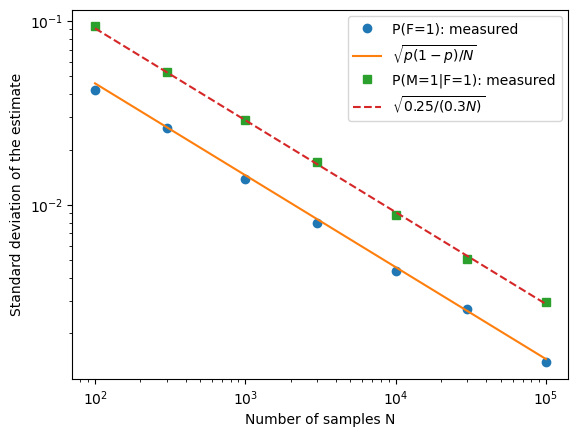

In [18]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

def sample_MF(N):
    """Draw N samples of (M, F) from the network. (G and P play no role in these probabilities.)"""
    M = rng.binomial(1, PM[1], N)
    F = rng.binomial(1, PF_M[1, M])
    return M, F

PF1 = (PF_M @ PM)[1]     # exact P(F=1) = 0.3
PM1_F1 = 0.5             # exact P(M=1 | F=1)

Ns = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
nrep = 200               # number of repeated experiments for each N
sd_F, sd_MgF = [], []
for N in Ns:
    errF, errM = [], []
    for _ in range(nrep):
        M, F = sample_MF(N)
        errF.append(F.mean() - PF1)                    # direct sampling estimate of P(F=1)
        keep = F == 1                                  # rejection sampling estimate of P(M=1 | F=1)
        errM.append(M[keep].mean() - PM1_F1 if keep.any() else np.nan)
    sd_F.append(np.std(errF)); sd_MgF.append(np.nanstd(errM))

plt.loglog(Ns, sd_F, 'o', label='P(F=1): measured')
plt.loglog(Ns, np.sqrt(PF1*(1-PF1)/Ns), '-', label=r'$\sqrt{p(1-p)/N}$')
plt.loglog(Ns, sd_MgF, 's', label='P(M=1|F=1): measured')
plt.loglog(Ns, np.sqrt(0.25/(0.3*Ns)), '--', label=r'$\sqrt{0.25/(0.3N)}$')
plt.xlabel('Number of samples N'); plt.ylabel('Standard deviation of the estimate')
plt.legend(); plt.show()

Both sets of points lie on lines of slope $-1/2$ in the log-log plot: to reduce the error by a factor of 10 we need 100 times as many samples. The conditional probability has a larger error than $P(F=True)$ for the same $N$ because only 30% of the samples are retained.

However, if we have specific questions we want to answer and are time or compute-limited, then we may wish for something more efficient. This will be our next topic.

### Likelihood weighting

Rejection sampling is simple and very general, but it is wasteful: every sample that disagrees with the evidence is thrown away, and if the evidence is unlikely then almost all of the samples will be discarded. **Likelihood weighting** avoids this by generating only samples that are consistent with the evidence.

Let's say that we want to compute the probability that someone with a career in programming but not in the finance sector studied mathematics, $P(M\vert S=True, F=False)$. Here $S$ and $F$ are the *evidence variables*: variables that are considered to be fixed by our accumulated knowledge (imagine we had "observed" them and found that they took these values).

We cannot simply fix the evidence variables to their observed values and sample everything else as before. That would give samples from the wrong distribution: for example, $M$ would be sampled from $P(M)$, which takes no account of the fact that observing $F=False$ makes $M=False$ more likely, because $F$ depends on $M$. We compensate by *weighting* each sample by the probability of the evidence given the values of its parents in that sample. In outline:

* Set the weight $w=1.0$.
* Visit the variables in order, parents before children.
* If the variable is *not* evidence, sample it from its conditional distribution given the values of its parents.
* If the variable *is* evidence, set it to its observed value and multiply the weight by the probability of that value given the values of its parents.
* Record the sample in the trace together with its weight $w$.

Let's illustrate this by working through our example.

* Set weight $w=1.0$.
* $G$ is not evidence. Sample from $P(G) = (0.6,0.4)$, suppose this returns False.
* $M$ is not evidence. Sample from $P(M) = (0.75,0.25)$, suppose this returns True.
* $F$ is an evidence variable and is fixed at False. Set $w\leftarrow w\times P(F=False\vert M=True) = 1.0\times 0.4 = 0.4$.
* $S$ is an evidence variable and is fixed at True. Set $w\leftarrow w\times P(S=True\vert M=True) = 0.4\times 0.55 = 0.22$.
* Record $(G,M,F,S) = (False, True, False, True)$ with weight 0.22.

We then count samples as before, but each sample counts in proportion to its weight: the estimate of $P(M=True\vert S=True,F=False)$ is the total weight of the samples in which $M$ is True divided by the total weight of all the samples. (If an evidence variable has no parents, as in some of the examples below, then its weight contribution is just its prior probability. This is the same for every sample and so cancels in the ratio.)

Why does this work? Firstly, all of the samples generated have the observed values of the evidence variables and so all of the samples can be used. This gives improved accuracy, or faster convergence for a given level of accuracy, compared to rejection sampling. Secondly, it can be shown rigorously that weighting by the likelihood of the evidence in this way is consistent with sampling from the desired posterior distribution. A proof can be found in the discussion of likelihood weighting in Russell and Norvig, *Artificial Intelligence: A Modern Approach* (Chapter 13 of the 4th edition; Chapter 14 of the 3rd edition). The main disadvantages are, firstly, a lack of flexibility: we have to fix the evidence variables, and if we want to compute for a different set of evidence then we have to regenerate a new trace. Secondly, if the evidence is unlikely, or appears late in the network, then most samples receive tiny weights and the estimate is dominated by a small number of samples.

Let's implement this.

Let us first generate something we know. We'll compute $P(\lnot F\vert M)$ We need to set $M=1$ as evidence.

In [19]:
N = 10000
Trace = np.zeros([N,5])
for i in range(N):
    w = 1.0
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Set M=1 as evidence and reweight
    M = 1
    w *= PM[M]
    # Draw one sample from P(F|M)
    F = np.random.binomial(1,PF_M[1,M])
    # Draw one sample from P(S|M)
    S = np.random.binomial(1,PS_M[1,M])
    Trace[i,:] = np.array([G,M,F,S,w])

# Since all rows of the trace are consistent with the evidence (ie conditioned on M=1) by construction, so we do the following
# Find all rows in the trace where F=0
FEq0MEq1 = Trace[np.where(Trace[:,2]==0)]
# Sum the weights in the subset of the trace we want, and divide by the sum of the weights in the full trace
PFEq0MEq1 = (FEq0MEq1[:,4].sum()) / Trace[:,4].sum()
print(f"P(F=0|M=1) = {PFEq0MEq1} (expected {PF_M[0,1]})")


P(F=0|M=1) = 0.3999 (expected 0.4)


Check another one of the inputs.

In [20]:
print(f"P(F=1|M=1) = {Trace[np.where(Trace[:,2]==1)][:,4].sum()/Trace[:,4].sum()} (expected {PF_M[1,1]})")
print(f"P(S=0|M=1) = {Trace[np.where(Trace[:,3]==0)][:,4].sum()/Trace[:,4].sum()} (expected {PS_M[0,1]})")
print(f"P(S=1|M=1) = {Trace[np.where(Trace[:,3]==1)][:,4].sum()/Trace[:,4].sum()} (expected {PS_M[1,1]})")


P(F=1|M=1) = 0.6001 (expected 0.6)
P(S=0|M=1) = 0.4493 (expected 0.45)
P(S=1|M=1) = 0.5507 (expected 0.55)


Now something that isn't an input: $P(M\vert F)$. We can compute exactly to check:

In [21]:
PF = PF_M @ PM
PM_F = (PF_M*PM).T/PF
print(f"P(M|F) = {PM_F}")

P(M|F) = [[0.85714286 0.5       ]
 [0.14285714 0.5       ]]


First fix $F=0$

In [22]:
N = 10000
Trace = np.zeros([N,5])
for i in range(N):
    w = 1.0
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Sample M
    M  = np.random.binomial(1,PM[1])
    # Set evidence
    F = 0
    w *= PF_M[F,M]
    # Draw one sample from P(S|M)
    S = np.random.binomial(1,PS_M[1,M])
    Trace[i,:] = np.array([G,M,F,S,w])

# Since all rows of the trace are consistent with the evidence by construction, so all we need to do is count the rows where $M=0$
print(f"P(M=0|F=0) = {Trace[np.where(Trace[:,1]==0)][:,4].sum()/Trace[:,4].sum()} (expected {PM_F[0,0]})")
print(f"P(M=1|F=0) = {Trace[np.where(Trace[:,1]==1)][:,4].sum()/Trace[:,4].sum()} (expected {PM_F[1,0]})")

P(M=0|F=0) = 0.8608532209375179 (expected 0.8571428571428572)
P(M=1|F=0) = 0.1391467790624822 (expected 0.14285714285714285)


Now for F=1

In [23]:
N = 10000
Trace = np.zeros([N,5])
for i in range(N):
    w = 1.0
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Sample M
    M  = np.random.binomial(1,PM[1])
    # Set evidence
    F = 1
    w *= PF_M[F,M]
    # Draw one sample from P(S|M)
    S = np.random.binomial(1,PS_M[1,M])
    Trace[i,:] = np.array([G,M,F,S,w])

# Since all rows of the trace are consistent with the evidence by construction, so all we need to do is count the rows where $M=0$
print(f"P(M=0|F=1) = {Trace[np.where(Trace[:,1]==0)][:,4].sum()/Trace[:,4].sum()} (expected {PM_F[0,1]})")
print(f"P(M=1|F=1) = {Trace[np.where(Trace[:,1]==1)][:,4].sum()/Trace[:,4].sum()} (expected {PM_F[1,1]})")

P(M=0|F=1) = 0.5065762984834251 (expected 0.5)
P(M=1|F=1) = 0.4934237015165749 (expected 0.4999999999999999)


Finally, let's compute $P(M\vert \lnot F,S)$. This is actually rather tricky to compute by hand, so let's compute by direct sampling:

In [24]:
N = 10000
Trace = np.zeros([N,4])
for i in range(N):
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Draw one sample from P(M)
    M = np.random.binomial(1,PM[1])
    # Draw one sample from P(F|M)
    F = np.random.binomial(1,PF_M[1,M])
    # Draw one sample from P(S|M)
    S = np.random.binomial(1,PS_M[1,M])
    Trace[i,:] = np.array([G,M,F,S])

# Rows where F=0
x = Trace[np.where(Trace[:,2]==0)]
# Rows where F=0 and S=1
x = x[np.where(x[:,3]==1)]

PM_NotFS = x[np.where(x[:,1]==1)].shape[0]/x.shape[0]
PNotM_NotFS = x[np.where(x[:,1]==0)].shape[0]/x.shape[0]

print(f"P(M=1|F=0,S=1) = {PM_NotFS}")
print(f"P(M=0|F=0,S=1) = {PNotM_NotFS}")

P(M=1|F=0,S=1) = 0.2055365946150929
P(M=0|F=0,S=1) = 0.7944634053849071


In [25]:
N = 10000
Trace = np.zeros([N,5])
for i in range(N):
    w = 1.0
    # Draw one sample from P(G)
    G = np.random.binomial(1,PG[1])
    # Sample M
    M  = np.random.binomial(1,PM[1])
    # Set evidence
    F = 0
    w *= PF_M[F,M]
    # Draw one sample from P(S|M)
    S = 1
    w *= PS_M[S,M]
    Trace[i,:] = np.array([G,M,F,S,w])

# Since all rows of the trace are consistent with the evidence by construction, so all we need to do is count the rows where $M=0$
print(f"P(M=0|F=0,S=1) = {Trace[np.where(Trace[:,1]==0)][:,4].sum()/Trace[:,4].sum()} (expected {PNotM_NotFS})")

print(f"P(M=1|F=0,S=1) = {Trace[np.where(Trace[:,1]==1)][:,4].sum()/Trace[:,4].sum()} (expected {PM_NotFS})")


P(M=0|F=0,S=1) = 0.787534383217967 (expected 0.7944634053849071)
P(M=1|F=0,S=1) = 0.21246561678203313 (expected 0.2055365946150929)


### Rejection sampling versus likelihood weighting

How much do we gain by using likelihood weighting? Suppose that the evidence is $F=True$ and $S=True$, and that we want $P(M=True\vert F=True,S=True)$, which can be calculated exactly from the distributions: $0.25\times0.6\times0.55/(0.25\times0.6\times0.55+0.75\times0.2\times0.35)\approx0.611$.

* Rejection sampling keeps only the samples in which the evidence occurs, which is a fraction $P(F=True,S=True)$ of the total.
* Likelihood weighting uses all of the samples but they have different weights. The weights are not all equal, so the number of samples that really count is smaller than $N$. A standard measure is the *effective sample size* $N_{\mathrm{eff}}=(\sum_i w_i)^2/\sum_i w_i^2$, which equals $N$ if all the weights are equal and is smaller if a few samples dominate.

We compare the number of samples that count in each method, and the standard deviation of the resulting estimates.

In [26]:
rng = np.random.default_rng(1)
exact = 0.25*0.6*0.55 / (0.25*0.6*0.55 + 0.75*0.2*0.35)

def rejection(N):
    M = rng.binomial(1, PM[1], N)
    F = rng.binomial(1, PF_M[1, M])
    S = rng.binomial(1, PS_M[1, M])
    keep = (F == 1) & (S == 1)
    return M[keep].mean() if keep.any() else np.nan, keep.sum()

def likelihood_weighting(N):
    M = rng.binomial(1, PM[1], N)                  # sample the non-evidence variable
    w = PF_M[1, M] * PS_M[1, M]                    # weight: probability of the evidence F=1 and S=1
    return (w * M).sum() / w.sum(), w.sum()**2 / (w**2).sum()

N, nrep = 1000, 500
rej = np.array([rejection(N) for _ in range(nrep)])
lw = np.array([likelihood_weighting(N) for _ in range(nrep)])

print(f"Exact P(M=1 | F=1, S=1) = {exact:.4f}")
print(f"Rejection sampling:   mean number of samples that count = {rej[:, 1].mean():6.1f},  sd of estimate = {np.nanstd(rej[:, 0]):.4f}")
print(f"Likelihood weighting: mean effective sample size        = {lw[:, 1].mean():6.1f},  sd of estimate = {np.std(lw[:, 0]):.4f}")

Exact P(M=1 | F=1, S=1) = 0.6111
Rejection sampling:   mean number of samples that count =  135.1,  sd of estimate = 0.0437
Likelihood weighting: mean effective sample size        =  590.1,  sd of estimate = 0.0177


Likelihood weighting makes better use of the samples. The gain here is a factor of 4 or so; it grows rapidly as the evidence becomes less probable. In the exercises on inference we will see an example where rejection sampling retains almost no samples.